# Data Ingestion, Cleaning & Preprocessing with Pandas
**Dataset:** `Customer_Segmentation.csv` — 51,000 customer records, 23 columns (demographic, location, contact and professional attributes)

**Goal:** load the raw data, audit it, fix missing values / invalid values / wrong data types, engineer new features, and export `clean_dataset.csv`.

**Workflow:** 1. Load → 2. Audit (BEFORE) → 3. Clean → 4. Feature engineering → 5. Audit (AFTER) → 6. Before/After comparison → 7. Export & verify

> **Note on feature engineering:** this dataset has no date or sales/profit columns, so "extract month/year" and "profit margin" don't apply. Instead I engineer equivalent derived features from the columns that exist (email domain, area code, time-zone region, etc.).

## 1. Load the raw dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

RAW_FILE = 'Customer_Segmentation.csv'
df_raw = pd.read_csv(RAW_FILE)
df = df_raw.copy()          # all cleaning happens on this copy; df_raw stays untouched for before/after
print('Shape:', df_raw.shape)
df_raw.head()

Shape: (51000, 23)


,first_name,last_name,title,gender,email,city,country,country_code,latitude,longitude,phone,street_address,street_name,street_number,street_suffix,time_zone,company_name,department,job_title,language,university,linkedin_skill,ip_address
0,Priscella,Pollett,Honorable,Agender,ppollett0@foxnews.com,Sesheke,Zambia,ZM,-17.473886,24.295514,222-398-8279,93 Fremont Drive,Green,90004,Crossing,Africa/Lusaka,Omba,Support,Internal Auditor,Indonesian,University of Zambia,Lifestyle,129.60.144.253
1,Ana,Onge,Mr,Male,aonge1@fda.gov,Querecotillo,Peru,PE,-4.838304,-80.648215,650-786-5808,0841 Troy Park,Gerald,9,Center,America/Lima,Cogidoo,Sales,Compensation Analyst,Fijian,Universidad Nacional de San Antonio Abad,Healthcare Industry,100.2.67.41
2,Butch,Rawls,Mrs,Male,brawls2@slideshare.net,Licupis,Peru,PE,-6.424052,-79.242648,325-412-0143,09450 Rowland Center,Eggendart,5104,Point,America/Lima,Edgewire,Support,Health Coach II,Gujarati,Universidad Nacional de San Martín,Visual SVN,48.161.197.47
3,Ambros,Fairrie,Rev,Male,afairrie3@reuters.com,Yonghe,China,CN,36.759507,110.632006,664-380-9221,5173 Nelson Alley,Annamark,8,Center,Asia/Harbin,Digitube,Support,General Manager,Belarusian,Fuzhou University,Nanofabrication,36.188.226.116
4,Gaylene,Titcomb,Honorable,Female,gtitcomb4@dyndns.org,Wang Yang,Thailand,TH,17.074088,104.449040,477-429-2626,833 Vermont Drive,Clarendon,994,Trail,Asia/Bangkok,Quaxo,Engineering,Internal Auditor,Papiamento,Mahachulalongkorn Buddhist University,AQL,181.24.84.57


In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   first_name      51000 non-null  str    
 1   last_name       51000 non-null  str    
 2   title           51000 non-null  str    
 3   gender          51000 non-null  str    
 4   email           51000 non-null  str    
 5   city            51000 non-null  str    
 6   country         51000 non-null  str    
 7   country_code    50966 non-null  str    
 8   latitude        51000 non-null  float64
 9   longitude       51000 non-null  float64
 10  phone           51000 non-null  str    
 11  street_address  51000 non-null  str    
 12  street_name     51000 non-null  str    
 13  street_number   51000 non-null  int64  
 14  street_suffix   51000 non-null  str    
 15  time_zone       51000 non-null  str    
 16  company_name    51000 non-null  str    
 17  department      51000 non-null  str    
 1

## 2. Audit of the RAW data (BEFORE cleaning)

In [3]:
STR_COLS = [c for c in df_raw.columns if pd.api.types.is_string_dtype(df_raw[c]) or df_raw[c].dtype == object]

def audit(d, name):
    phone_ok = d['phone'].astype('string').str.fullmatch(r'\d{3}-\d{3}-\d{4}')
    ws = sum(int((d[c].dropna().astype(str) != d[c].dropna().astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()).sum()) for c in STR_COLS)
    return pd.Series({
        'rows': len(d),
        'columns': d.shape[1],
        'missing values (total)': int(d.isna().sum().sum()),
        'duplicate rows': int(d.duplicated().sum()),
        'duplicate emails': int(d['email'].str.lower().duplicated().sum()),
        'cells with extra/leading/trailing spaces': ws,
        'invalid phone numbers': int((phone_ok == False).sum()),
        'emails not lowercase': int((d['email'] != d['email'].str.lower()).sum()),
        'lat/long out of valid range': int((~d['latitude'].between(-90, 90) | ~d['longitude'].between(-180, 180)).sum()),
    }, name=name)

audit_before = audit(df_raw, 'BEFORE')
audit_before.to_frame()

,BEFORE
rows,51000
columns,23
missing values (total),34
duplicate rows,0
duplicate emails,0
cells with extra/leading/trailing spaces,85
invalid phone numbers,1
emails not lowercase,0
lat/long out of valid range,0


In [4]:
missing_before = df_raw.isna().sum()
print('Columns with missing values:'); print(missing_before[missing_before > 0])
print('\nCountries behind the missing country_code:'); print(df_raw.loc[df_raw['country_code'].isna(), 'country'].value_counts())

Columns with missing values:
country_code    34
dtype: int64

Countries behind the missing country_code:
country
Namibia    34
Name: count, dtype: int64


In [5]:
print('Invalid phone number(s):')
bad = ~df_raw['phone'].str.fullmatch(r'\d{3}-\d{3}-\d{4}')
print(df_raw.loc[bad, ['first_name','last_name','email','phone']])
print('\nCountry values with stray spaces:', df_raw.loc[df_raw['country'] != df_raw['country'].str.strip(), 'country'].unique())
print('Example university values with stray spaces:')
print(df_raw.loc[df_raw['university'].str.contains(r'^\s|\s$|\s{2,}'), 'university'].head(4).tolist())

Invalid phone number(s):
      first_name   last_name                      email      phone
35542       Edin  Stidworthy  estidworthyf2@cornell.edu  -247-7524

Country values with stray spaces: <StringArray>
['Bonaire, Saint Eustatius and Saba ']
Length: 1, dtype: str
Example university values with stray spaces:
['Bule Hora  University', 'St. Petersburg StateMechnikov  Medical Academy', 'University for Information Science and Technology  "St. Paul The Apostle" ', 'Central Academy of  Fine Art']


In [6]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,51000.0,24.785394,24.522517,-54.80795,7.590523,30.826141,44.303742,78.221061
longitude,51000.0,44.021854,70.311057,-178.16551,3.367186,38.101695,111.877499,179.350460
street_number,51000.0,11071.446275,23366.976562,0.00000,21.000000,439.000000,6760.250000,99997.000000


## 3. Cleaning

### 3.1 Standardise text (trim and collapse repeated spaces) and lowercase emails

In [7]:
str_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
for c in str_cols:
    df[c] = df[c].str.replace(r'\s+', ' ', regex=True).str.strip()
df['email'] = df['email'].str.lower()
print('Text columns standardised:', len(str_cols))

Text columns standardised: 20


### 3.2 Duplicates

In [8]:
print('Fully duplicated rows      :', df.duplicated().sum())
print('Duplicate emails           :', df['email'].duplicated().sum())
print('Duplicate IP addresses     :', df['ip_address'].duplicated().sum())
print('Duplicate first+last+email :', df.duplicated(['first_name','last_name','email']).sum())
# Same phone shared by two *different* customers (different names/emails) -> not a duplicate record, so rows are kept
print('Phone numbers shared by 2 customers:', df['phone'].duplicated(keep=False).sum(), 'rows (different people, kept)')
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows removed:', before - len(df))

Fully duplicated rows      : 0
Duplicate emails           : 0
Duplicate IP addresses     : 0
Duplicate first+last+email : 0
Phone numbers shared by 2 customers: 2 rows (different people, kept)


Rows removed: 0


### 3.3 Missing values
`country_code` is empty for **all 34 Namibia rows**. Namibia's ISO 3166-1 alpha-2 code is `NA`; it was lost upstream, so it is imputed from the known country → code mapping (a logical fill, not a guess).

In [9]:
assert df.loc[df['country_code'].isna(), 'country'].unique().tolist() == ['Namibia']
df.loc[df['country'] == 'Namibia', 'country_code'] = 'NA'
print('Missing country_code after fix:', df['country_code'].isna().sum())

Missing country_code after fix: 0


### 3.4 Invalid values
One phone number (`-247-7524`) has no area code, so it can't be repaired — it is set to missing rather than invent digits.

In [10]:
valid_phone = df['phone'].str.fullmatch(r'\d{3}-\d{3}-\d{4}')
print('Invalid phones set to NaN:', (~valid_phone).sum())
df.loc[~valid_phone, 'phone'] = np.nan

Invalid phones set to NaN: 1


### 3.5 Outlier check

In [11]:
# Latitude / longitude must lie in valid geographic ranges
assert df['latitude'].between(-90, 90).all() and df['longitude'].between(-180, 180).all()
print('latitude/longitude: all within valid range')

# street_number: IQR check
q1, q3 = df['street_number'].quantile([.25, .75]); iqr = q3 - q1
n_out = ((df['street_number'] < q1 - 1.5*iqr) | (df['street_number'] > q3 + 1.5*iqr)).sum()
print(f'street_number IQR-flagged values: {n_out} (range {df.street_number.min()}-{df.street_number.max()})')

latitude/longitude: all within valid range
street_number IQR-flagged values: 8496 (range 0-99997)


**Decision:** `street_number` is an address identifier, not a quantity — large house numbers (up to 99,997) are valid, so the IQR "outliers" are **kept** and not capped. Capping an identifier would corrupt real addresses. Coordinates are all in range, so no action is needed.

### 3.6 Fix data types

In [12]:
# street_number is an identifier -> string (no arithmetic should be done on it)
df['street_number'] = df['street_number'].astype(str)

# low-cardinality text columns -> category (smaller memory, correct semantics)
cat_cols = ['title','gender','country','country_code','street_suffix','department','language']
for c in cat_cols:
    df[c] = df[c].astype('category')
df[['latitude','longitude']] = df[['latitude','longitude']].astype('float64')
df.dtypes

first_name             str
last_name              str
title             category
gender            category
email                  str
city                   str
country           category
country_code      category
latitude           float64
longitude          float64
phone                  str
street_address         str
street_name            str
street_number          str
street_suffix     category
time_zone              str
company_name           str
department        category
job_title              str
language          category
university             str
linkedin_skill         str
ip_address             str
dtype: object

### 3.7 Consistency checks

In [13]:
assert df.groupby('country', observed=True)['country_code'].nunique().max() == 1, 'country -> multiple codes'
assert df.groupby('country_code', observed=True)['country'].nunique().max() == 1, 'code -> multiple countries'
assert df['email'].str.fullmatch(r'[^@\s]+@[^@\s]+\.[^@\s]+').all()
assert df['ip_address'].str.fullmatch(r'(\d{1,3}\.){3}\d{1,3}').all()
assert df['email'].is_unique
print('country <-> country_code is 1:1, emails valid & unique, IPs valid')

country <-> country_code is 1:1, emails valid & unique, IPs valid


## 4. Feature engineering

No date or revenue columns exist, so these features are derived from available fields:

| New feature | Derived from | Use |
|---|---|---|
| `full_name` | first_name + last_name | readable customer name |
| `email_domain`, `email_tld` | email | organisation / domain segmentation |
| `is_free_email` | email_domain | personal vs corporate segmentation |
| `area_code` | phone | regional grouping |
| `has_valid_phone` | phone | contactability flag |
| `tz_region` | time_zone | continent-level region (Africa, America, Asia…) |

In [14]:
df['full_name']   = df['first_name'] + ' ' + df['last_name']
df['email_domain'] = df['email'].str.split('@').str[1]
df['email_tld']   = df['email_domain'].str.rsplit('.', n=1).str[-1]
free = {'gmail.com','yahoo.com','hotmail.com','outlook.com','live.com','aol.com','icloud.com','gmx.com','mail.com','yandex.ru','163.com','qq.com','mail.ru','rediffmail.com','protonmail.com'}
df['is_free_email'] = df['email_domain'].isin(free)
df['area_code']   = df['phone'].str[:3]
df['has_valid_phone'] = df['phone'].notna()
df['tz_region']   = df['time_zone'].str.split('/').str[0].astype('category')
df[['full_name','email_domain','email_tld','is_free_email','area_code','has_valid_phone','tz_region']].head()

,full_name,email_domain,email_tld,is_free_email,area_code,has_valid_phone,tz_region
0,Priscella Pollett,foxnews.com,com,False,222,True,Africa
1,Ana Onge,fda.gov,gov,False,650,True,America
2,Butch Rawls,slideshare.net,net,False,325,True,America
3,Ambros Fairrie,reuters.com,com,False,664,True,Asia
4,Gaylene Titcomb,dyndns.org,org,False,477,True,Asia


## 5. Audit of the CLEAN data (AFTER cleaning)

In [15]:
STR_COLS = [c for c in df_raw.columns if pd.api.types.is_string_dtype(df_raw[c]) or df_raw[c].dtype == object]
df_check = df.copy()
df_check['street_number'] = pd.to_numeric(df_check['street_number'])
for c in df_check.select_dtypes('category').columns: df_check[c] = df_check[c].astype(str)
audit_after = audit(df_check[df_raw.columns], 'AFTER')
audit_after.to_frame()

,AFTER
rows,51000
columns,23
missing values (total),1
duplicate rows,0
duplicate emails,0
cells with extra/leading/trailing spaces,0
invalid phone numbers,0
emails not lowercase,0
lat/long out of valid range,0


## 6. Before vs After

In [16]:
comparison = pd.concat([audit_before, audit_after], axis=1)
comparison['fixed'] = comparison['BEFORE'] - comparison['AFTER']
comparison

,BEFORE,AFTER,fixed
rows,51000,51000,0
columns,23,23,0
missing values (total),34,1,33
duplicate rows,0,0,0
duplicate emails,0,0,0
cells with extra/leading/trailing spaces,85,0,85
invalid phone numbers,1,0,1
emails not lowercase,0,0,0
lat/long out of valid range,0,0,0


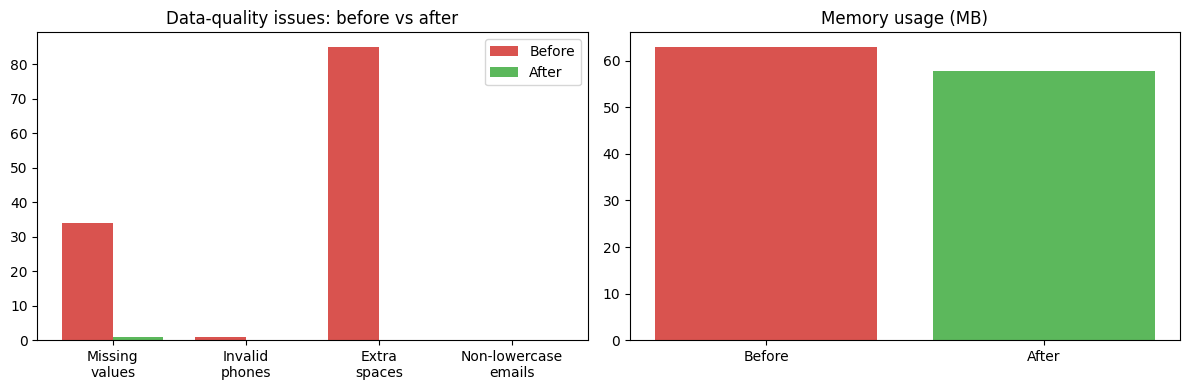

Memory: 63.0 MB -> 57.7 MB (includes 7 new feature columns)
Shape: (51000, 23) -> (51000, 30)


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
metrics = ['missing values (total)','invalid phone numbers','cells with extra/leading/trailing spaces','emails not lowercase']
x = np.arange(len(metrics)); w = .38
ax[0].bar(x - w/2, comparison.loc[metrics, 'BEFORE'], w, label='Before', color='#d9534f')
ax[0].bar(x + w/2, comparison.loc[metrics, 'AFTER'],  w, label='After',  color='#5cb85c')
ax[0].set_xticks(x); ax[0].set_xticklabels(['Missing\nvalues','Invalid\nphones','Extra\nspaces','Non-lowercase\nemails'])
ax[0].set_title('Data-quality issues: before vs after'); ax[0].legend()

mem_b = df_raw.memory_usage(deep=True).sum()/1e6; mem_a = df.memory_usage(deep=True).sum()/1e6
ax[1].bar(['Before','After'], [mem_b, mem_a], color=['#d9534f','#5cb85c'])
ax[1].set_title('Memory usage (MB)')
plt.tight_layout(); plt.show()
print(f'Memory: {mem_b:.1f} MB -> {mem_a:.1f} MB (includes 7 new feature columns)')
print('Shape:', df_raw.shape, '->', df.shape)

In [18]:
print('Missing values per column (AFTER):')
m = df.isna().sum(); print(m[m > 0] if m.sum() else 'none'); print('\nRegion distribution:'); print(df['tz_region'].value_counts())

Missing values per column (AFTER):
phone        1
area_code    1
dtype: int64

Region distribution:
tz_region
Asia         24168
Europe       14310
America       8634
Africa        3197
Indian         313
Pacific        276
Atlantic        57
Australia       44
Arctic           1
Name: count, dtype: int64


## 7. Export the clean dataset

In [19]:
df.to_csv('clean_dataset.csv', index=False)

# Verify the saved file. keep_default_na=False is IMPORTANT: Namibia's code is the text "NA",
# which pandas would otherwise misread as a missing value when reloading.
chk = pd.read_csv('clean_dataset.csv', keep_default_na=False, na_values=[''])
print('Saved clean_dataset.csv ->', chk.shape)
print('Namibia country_code in file:', chk.loc[chk.country == 'Namibia', 'country_code'].unique())
print('Remaining missing values:', chk.isna().sum()[chk.isna().sum() > 0].to_dict())
assert len(chk) == len(df) and list(chk.columns) == list(df.columns)

Saved clean_dataset.csv -> (51000, 30)
Namibia country_code in file: <StringArray>
['NA']
Length: 1, dtype: str
Remaining missing values: {'phone': 1, 'area_code': 1}


## Summary of what was done
* **Loaded** 51,000 rows × 23 columns.
* **Missing values:** 34 empty `country_code` (all Namibia) → filled with `NA`.
* **Invalid data:** 1 malformed phone number (no area code) → set to missing.
* **Text cleaning:** trailing/leading/double spaces removed (country, university); emails lowercased.
* **Duplicates:** none found (0 duplicate rows, emails or IPs).
* **Outliers:** coordinates valid; `street_number` extremes are legitimate identifiers → kept.
* **Data types:** `street_number` → string; low-cardinality columns → category.
* **Features added:** 7 (`full_name`, `email_domain`, `email_tld`, `is_free_email`, `area_code`, `has_valid_phone`, `tz_region`).
* **Data observation:** `street_number` does not match the number inside `street_address` (e.g. row 0: 90004 vs 93), so no address feature was built from it; `street_address` is kept as the reliable address field.
* **Exported:** `clean_dataset.csv` (51,000 rows × 30 columns).